In [1]:
from src.circstudio.analysis import *
import os

In [2]:
import src.circstudio as cs

In [3]:
import matplotlib.pyplot as plt

In [4]:
# Create file path for sample files within the circStudio package
fpath = os.path.join(os.path.dirname(cs.__file__))

# Create a new Raw instance using awd RPX adaptor
raw = cs.io.read_rpx(os.path.join(fpath, 'data', 'test_sample_rpx_eng.csv'),
                             start_time='2015-07-04 12:00:00',
                             light_mode='White Light',
                             period='6 days',
                             language='ENG_UK')

In [5]:
# Hilaire correction
# Create instance of ModelComparer
comparer = cs.ModelComparer(data=raw.light, equilibrate=True, hilaire_correction=True)

# Fit a line to the phase prediction by HannaySP
comparer.linearize_phase(change_params=True)

# Find the optimal translation parameters
comparer.find_optimal_params(change_params=True)

# Predict Forger trace
comparer.predict_forger(change_params=True)

# Compute the cumulative rmse
crmse_x, crmse_xc = comparer.cumulative_rmse()

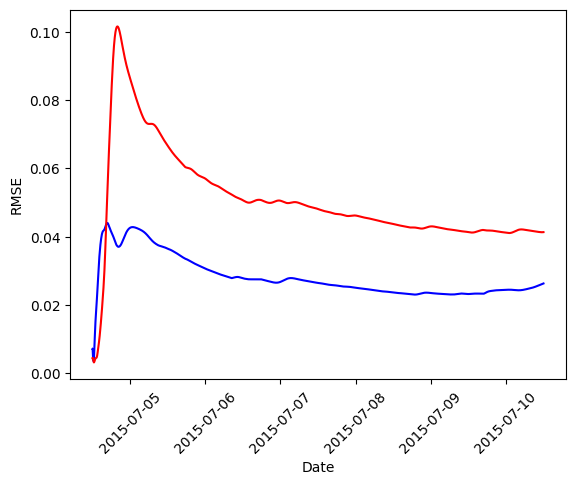

In [6]:
# Define color map to plot crmse_x and crmse_xc
errors = {'blue': crmse_x, 'red': crmse_xc}

# Plot the two curves
for error in errors.keys():
    plt.plot(raw.light.index, errors[error], color=error)

# Rotate xticks
plt.xticks(rotation=45)

# Label x and y axis
plt.xlabel('Date')
plt.ylabel('RMSE')

# Show the figure
plt.show()

### Hilaire model

In [4]:
hilaire07 = cs.Hilaire07(data=raw.light)

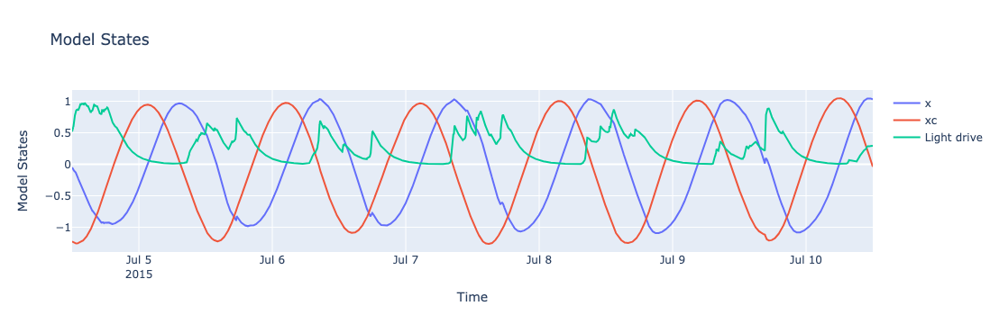

In [5]:
hilaire07.plot(states=True)

In [4]:
skeldon23 = cs.Skeldon23(data=raw.light)

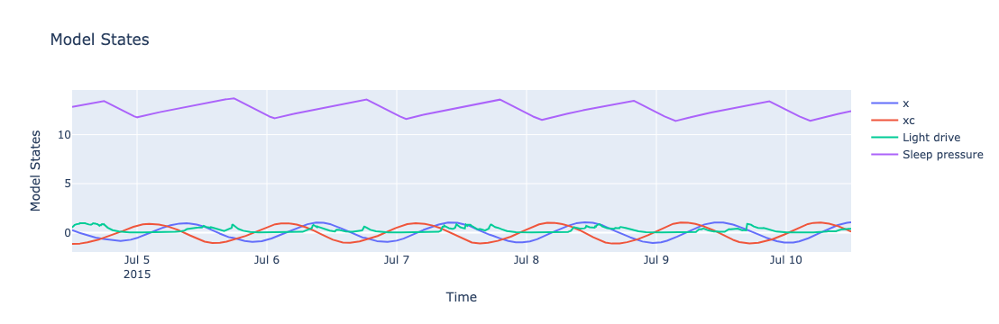

In [6]:
skeldon23.run()
skeldon23.plot(states=True)

In [2]:
import plotly.graph_objs as go

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from scipy import stats

### Model Comparer

In [14]:
periods = ['p1', 'p2', 'p3']
rows = []
for period in periods:
    source = os.path.join('..','..', '..', 'SubmarineProject', 'data','processed','txt_divided', period)
    for filename in os.listdir(source):
        fpath = os.path.join(source, filename)
        if os.path.isfile(fpath) and filename.endswith('.txt'):
            # Create a row instance of an atr file
            raw = circstudio.io.read_atr(fpath)

            # Create a ModelComparer model instance
            comparison = ModelComparer(data=raw.light, equilibrate=True)

            # Fit the model
            comparison.linearize_phase(change_params=True)
            comparison.find_optimal_params(change_params=True)
            comparison.predict_forger(change_params=True)
    
            rmse_x, rmse_xc = comparison.rmse()
    
            rows.append({
                'sb_id': os.path.splitext(filename)[0],
                'period': period,
                'rmse_x': rmse_x,
                'rmse_xc': rmse_xc,
                'IS_light': IS(data=raw.light),
                'IV_light': IV(data=raw.light),
            })
output = pd.DataFrame(rows)

In [17]:
output

,sb_id,period,rmse_x,rmse_xc,IS_light,IV_light
0,sb_23,p1,0.050524,0.056183,0.235934,0.287179
1,sb_22,p1,0.062053,0.068518,0.169062,0.581420
2,sb_08,p1,0.091881,0.103011,0.102111,0.350959
3,sb_20,p1,0.078744,0.088273,0.159109,0.504498
4,sb_21,p1,0.058205,0.071532,0.176590,0.377575
...,...,...,...,...,...,...
75,sb_05,p3,0.051638,0.058921,0.125046,0.518121
76,sb_11,p3,0.136524,0.131212,0.119491,0.457191
77,sb_07,p3,0.239986,0.231869,0.141684,0.573808
78,sb_13,p3,0.089725,0.101942,0.082762,0.577134


In [5]:
periods = ['p1', 'p2', 'p3']
rows = []
for period in periods:
    source = os.path.join('..','..', '..', 'SubmarineProject', 'data','processed','txt_divided', period)
    for filename in os.listdir(source):
        fpath = os.path.join(source, filename)
        if os.path.isfile(fpath) and filename.endswith('.txt'):
            # Create a row instance of an atr file
            raw = circstudio.io.read_atr(fpath)
            comparison = ModelComparer(data=raw.light, equilibrate=True)
            comparison.linearize_phase(change_params=True)
            comparison.find_optimal_params(change_params=True)
            comparison.predict_forger(change_params=True)
    
            crmse_x, crmse_xc = comparison.cumulative_rmse()
    
            rows.append({
                'sb_id': os.path.splitext(filename)[0],
                'period': period,
                'crmse_x': crmse_x,
                'crmse_xc': crmse_xc,
                'IS_light': IS(data=raw.light),
                'IV_light': IV(data=raw.light),
            })
output = pd.DataFrame(rows)

In [6]:
output.to_csv('modelcomparer_eq_crmse.csv', index=False)

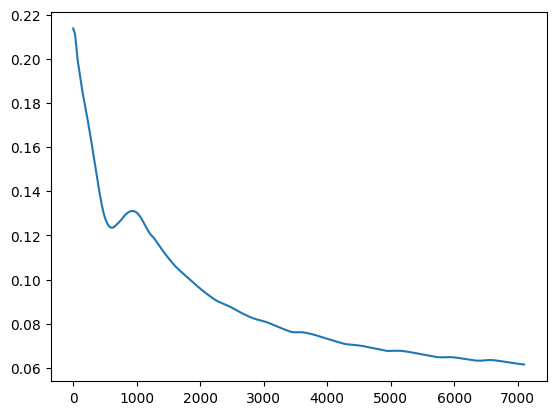

In [23]:
sample_1 = output['crmse_x'][5]
plt.plot(sample_1) # Sample from P1

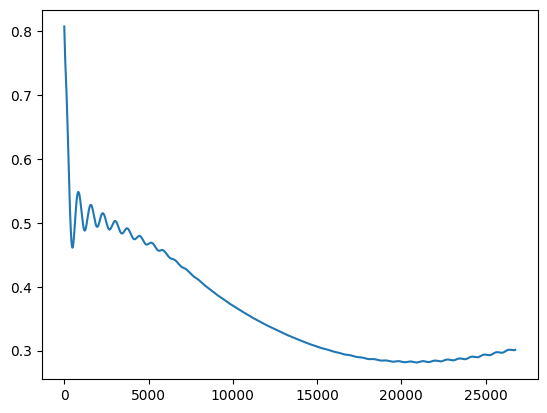

In [24]:
sample_1 = output['crmse_x'][35]
plt.plot(sample_1) # Using a sample from P2

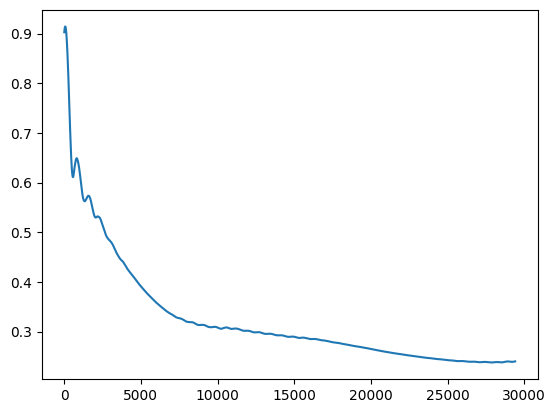

In [29]:
sample_1 = output['crmse_x'][77]
plt.plot(sample_1) # Using a sample from P3

<Axes: xlabel='rmse_x', ylabel='IV_light'>

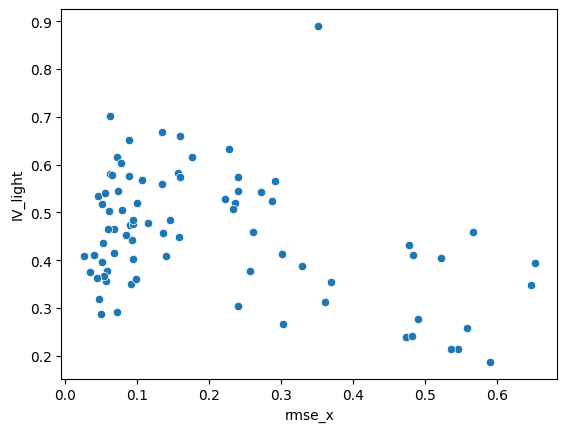

In [18]:
#data_p1 = output[output['period'] == 'p1']
sns.scatterplot(data=output, x='rmse_x', y='IV_light')

In [40]:
data_filtered = output[(output['period'] == 'p2') | (output['period'] == 'p3')]

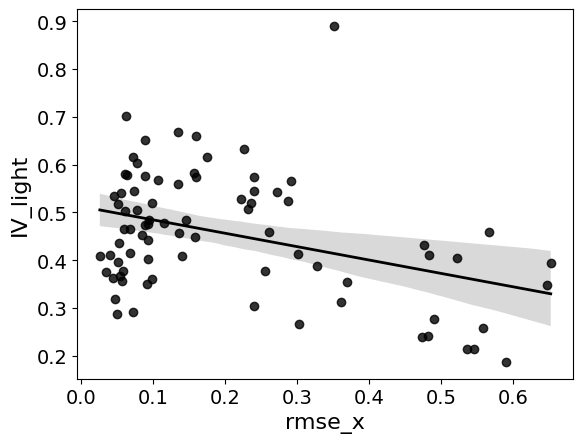

In [55]:
#sns.scatterplot(data=data_p1, x='rmse_x', y='IV_light', palette='viridis', s=100)
sns.regplot(data=output, x='rmse_x', y='IV_light', scatter=True, color='black', line_kws={'linewidth': 2})
plt.xlabel('rmse_x', fontsize=16)
plt.ylabel('IV_light', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

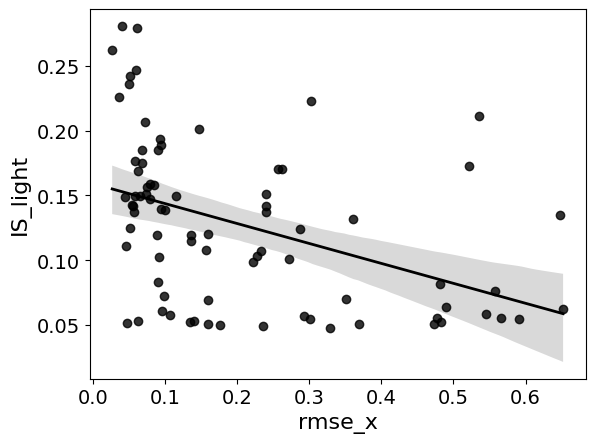

In [56]:
#sns.scatterplot(data=data_p1, x='rmse_x', y='IV_light', palette='viridis', s=100)
sns.regplot(data=output, x='rmse_x', y='IS_light', scatter=True, color='black', line_kws={'linewidth': 2})
plt.xlabel('rmse_x', fontsize=16)
plt.ylabel('IS_light', fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [51]:
rho, pval = stats.spearmanr(output['rmse_x'], output['IS_light'])
print(f'rho = {rho:.3f}, p-value = {pval}')

rho = -0.498, p-value = 2.592955660148834e-06


In [54]:
rho, pval = stats.spearmanr(output['rmse_x'], output['IV_light'])
print(f'rho = {rho:.3f}, p-value = {pval}')

rho = -0.197, p-value = 0.07927720683755403


,sb_id,period,rmse_x,rmse_xc,IS_light,IV_light
0,sb_23,p1,0.164303,0.154229,0.235934,0.287179
1,sb_22,p1,0.147134,0.143399,0.169062,0.581420
2,sb_08,p1,0.102852,0.114371,0.102111,0.350959
3,sb_20,p1,0.183614,0.176406,0.159109,0.504498
4,sb_21,p1,0.161272,0.164680,0.176590,0.377575
...,...,...,...,...,...,...
75,sb_05,p3,0.110210,0.106570,0.125046,0.518121
76,sb_11,p3,0.223029,0.211603,0.119491,0.457191
77,sb_07,p3,0.166431,0.157849,0.141684,0.573808
78,sb_13,p3,0.217984,0.213312,0.082762,0.577134


In [ ]:
periods = ['p1', 'p2', 'p3']
rows = []
for period in periods:
    source = os.path.join('..','..', '..', 'SubmarineProject', 'data','processed','txt_divided', period)
    for filename in os.listdir(source):
        fpath = os.path.join(source, filename)
        if os.path.isfile(fpath) and filename.endswith('.txt'):
            # Create a row instance of an atr file
            raw = circstudio.io.read_atr(fpath)
            comparison = ModelComparer(data=raw.light, equilibrate=True)
            comparison.linearize_phase(change_params=True)
            comparison.find_optimal_params(change_params=True)
            comparison.predict_forger(change_params=True)

            # Compute the comparison half_life_crmse
            print(comparison.half_life_crmse())
            break

(np.float64(35.14858853955029), np.float64(67.95655447559271))


### LIDS

This class analyzes locomotor activity during sleep.

Workflow:

raw activity (sleep only)

        ↓
        
lids_transform()

        ↓
        
lids_fit()

        ↓
        
metrics (period, MRI, phases)

In [5]:
fpath = os.path.join(os.path.dirname(circstudio.__file__))
#raw = circStudio.io.read_atr(os.path.join(fpath, 'data', 'test_sample_atr.txt'))
raw = circstudio.io.read_awd(os.path.join(fpath, 'data', 'example_01.AWD'),
                             start_time='1918-01-24 08:00:00',
                             period='9 days')

In [6]:
lids = LIDS(
    lids_func='lids',
    fit_func='cosine',      # or 'chirp', 'modchirp'
    fit_obj_func='residuals'
)

In [7]:
smooth_lids = lids.lids_transform(
    ts=raw.activity,
    method='mva',
    win_td='30min',
    resampling_freq=None
)

In [8]:
lids.lids_fit(
    smooth_lids,
    scan_period=True,
    bounds=('30min', '180min'),
    step='5min',
    verbose=True
)

[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 33
    # data points      = 12961
    # variables        = 3
    chi-square         = 17686642.4
    reduced chi-square = 1364.92070
    Akaike info crit   = 93566.5353
    Bayesian info crit = 93588.9444
[[Variables]]
    amp:     0.00949689 +/- 0.44945695 (4732.68%) (init = 50)
    phase:  -0.09453026 +/- 46.3887721 (49072.93%) (init = 0)
    period:  30 (fixed)
    delta:   38.0877544 +/- 0.56203293 (1.48%) (init = 60)
    offset:  38.0782575 +/- 0.32465150 (0.85%) == 'delta-amp'
[[Correlations]] (unreported correlations are < 0.100)
    C(amp, delta) = +0.8165
Pearson r: 0.00018175523531665627
MRI: 3.452217706647653e-06
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 29
    # data points      = 12961
    # variables        = 3
    chi-square         = 17686552.6
    reduced chi-square = 1364.91377
    Akaike info crit   = 93566.4696
    Bayesian info crit = 93588.8787
[[Variabl

In [1]:
period = lids.lids_period(freq='min')
print(period)

NameError: name 'lids' is not defined

In [10]:
mri = lids.lids_mri(smooth_lids)
print(mri)

0.4314924367692274


In [13]:
r, p = lids.lids_pearson_r(smooth_lids)

In [15]:
r

np.float64(0.0642638404509406)

In [12]:
onset, offset = lids.lids_phases(smooth_lids)

In [13]:
summary = lids.lids_summary(
    lids=[lids1, lids2, lids3], # example of selecting multiple sleep bouts.
    verbose=True
)

NameError: name 'lids1' is not defined

### FLM

In [5]:
fpath = os.path.join(os.path.dirname(circstudio.__file__))
#raw = circStudio.io.read_atr(os.path.join(fpath, 'data', 'test_sample_atr.txt'))
raw = circstudio.io.read_awd(os.path.join(fpath, 'data', 'example_01.AWD'),
                             start_time='1918-01-24 08:00:00',
                             period='9 days')

In [6]:
# Resampling frequency for the daily activity profile
freq='1min'

# The number of basis functions is max_order*2+1 (1 constant + n cosine functions + n sine functions)
max_order = 9

In [7]:
flm = FLM(basis='fourier',sampling_freq=freq,max_order=max_order)

In [8]:
# By setting the "verbose" parameter to True, the result of least-square fit is displayed:
flm.fit(raw.activity,verbose=True)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.731
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     214.7
Date:                Thu, 12 Feb 2026   Prob (F-statistic):               0.00
Time:                        14:59:21   Log-Likelihood:                -8390.5
No. Observations:                1440   AIC:                         1.682e+04
Df Residuals:                    1421   BIC:                         1.692e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        170.9896      2.178     78.523      0.0

In [9]:
flm_est = flm.evaluate(raw.activity)

In [10]:
daily_avg = daily_profile(raw.activity)

In [11]:
# set x-axis labels and their corresponding data values
labels = ['00:00', '06:00', '12:00', '18:00']
tickvals = ['00:00:00', '06:00:00', '12:00:00', '18:00:00']

layout = go.Layout(
    autosize=False, width=900, height=600,
    title="Daily profile",
    xaxis=dict(
        title="Time of day (HH:MM)",
        ticktext=labels,
        tickvals=tickvals),
    yaxis=dict(title="Counts (a.u)"),
    shapes=[], showlegend=True)

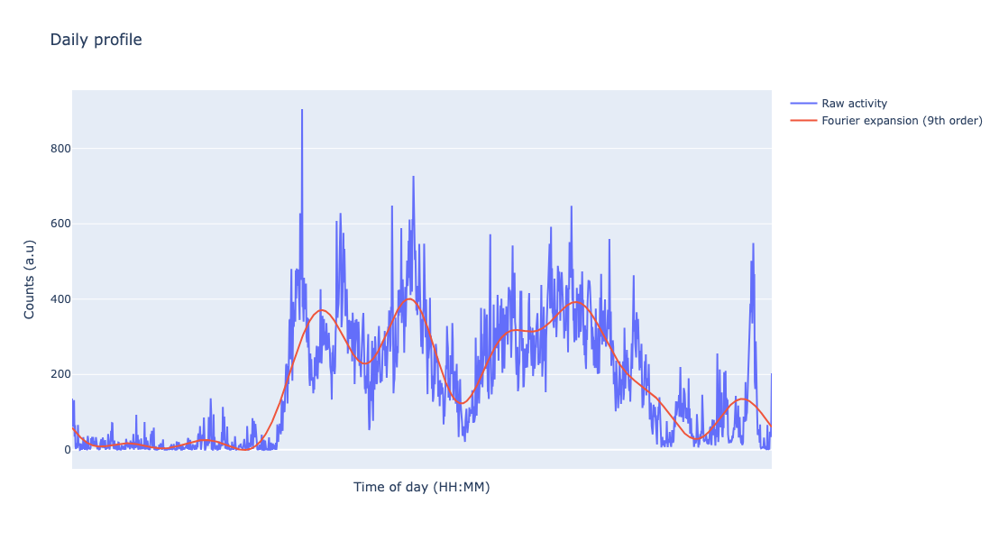

In [12]:
go.Figure(data=[
    go.Scatter(x=daily_avg.index.astype(str),y=daily_avg,name='Raw activity'),
    go.Scatter(x=daily_avg.index.astype(str),y=flm_est,name='Fourier expansion (9th order)')
],layout=layout)

In [13]:
daily_avg = daily_profile(raw.activity)

In [14]:
flm_spline = FLM(basis='spline',sampling_freq='30min',max_order=3)

In [15]:
flm_spline.fit(raw.activity, verbose=False)

In [16]:
# The "r" parameter represents the ratio between the number of points at which the spline is evaluated and the original number of points.
r = 10

In [17]:
spline_est = flm_spline.evaluate(r=r)

In [18]:
t = np.linspace(0,daily_avg.index.size,daily_avg.index.size,endpoint=True)

In [19]:
t_10 = np.linspace(0,daily_avg.index.size,daily_avg.index.size*r,endpoint=True)

In [20]:
data = [go.Scatter(x=t,y=daily_avg,name='Raw activity'),
        go.Scatter(x=t_10,y=spline_est,name='B-spline')
       ]

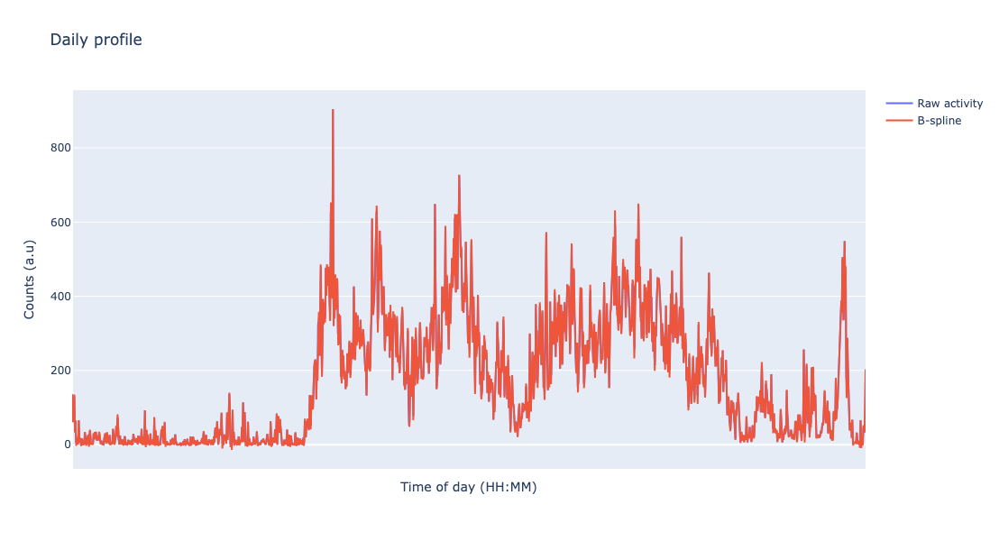

In [21]:
go.Figure(data=data, layout=layout)

In [22]:
daily_avg = daily_profile(raw.activity)

In [23]:
names = ['Raw activity', 'Scott', 'Silverman', 'Bandwith: 20']

In [24]:
daily_avg_smoothed = []

In [25]:
daily_avg_smoothed.append(flm.smooth_daily_profile(raw.activity, method='scott', verbose=True))

Kernel size used to smooth the data: 39.16586876177629


In [26]:
daily_avg_smoothed.append(flm.smooth_daily_profile(raw.activity, method='silverman', verbose=True))

Kernel size used to smooth the data: 33.28544087403084


In [27]:
daily_avg_smoothed.append(flm.smooth_daily_profile(raw.activity, method=20))

In [28]:
data = [go.Scatter(x=daily_avg.index.astype(str),y=daily_avg_smoothed[n], name=names[n+1]) for n in range(0,len(daily_avg_smoothed))]

In [29]:
data.insert(0,go.Scatter(x=daily_avg.index.astype(str),y=daily_avg,name=names[0]))

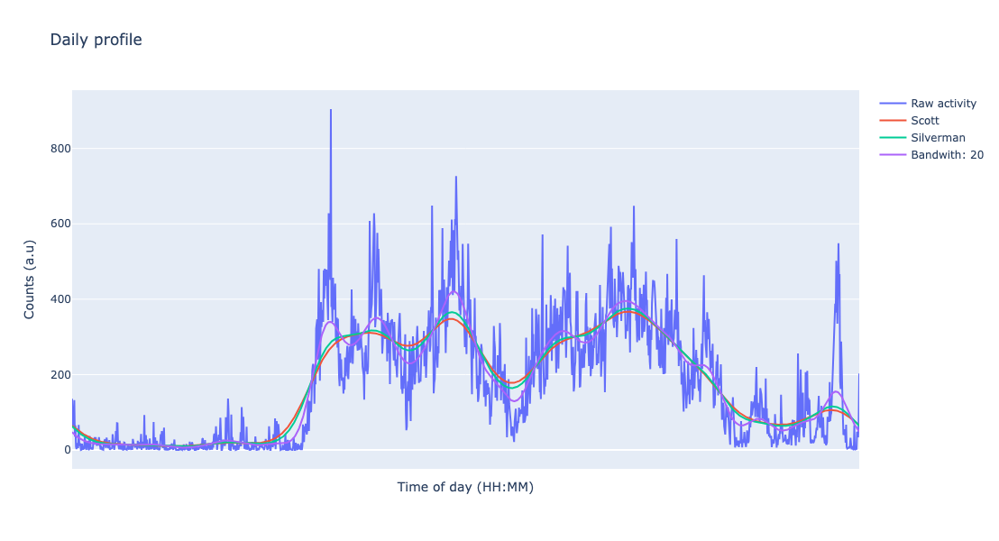

In [30]:
go.Figure(data=data,layout=layout)

In [31]:
ts_avg_smoothed = []

In [32]:
ts_avg_smoothed.append(flm.smooth_timeseries(raw.activity, method='scott', verbose=True))

Kernel size used to smooth the data: 28.587203569652328


In [33]:
ts_avg_smoothed.append(flm.smooth_timeseries(raw.activity, method='silverman', verbose=True))

Kernel size used to smooth the data: 24.29507385522861


In [34]:
ts_avg_smoothed.append(flm.smooth_timeseries(raw.activity, method=20, verbose=True))

Kernel size used to smooth the data: 20


In [35]:
data = [go.Scatter(x=raw.activity.index.astype(str),y=ts_avg_smoothed[n], name=names[n+1]) for n in range(0,len(ts_avg_smoothed))]

In [36]:
data.insert(0,go.Scatter(x=raw.activity.index.astype(str),y=raw.activity,name=names[0]))

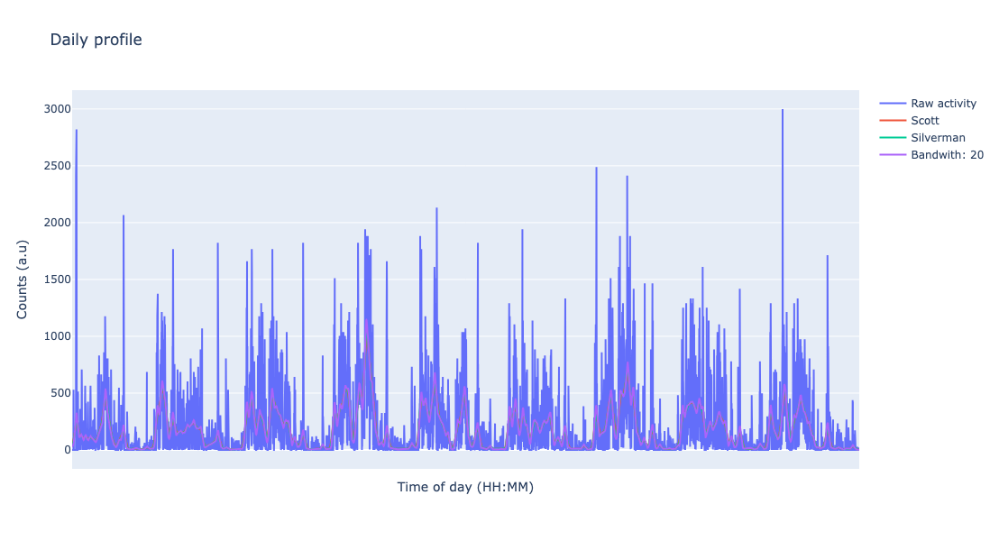

In [37]:
go.Figure(data=data,layout=layout)

### Fractal

In [6]:
from plotly.subplots import make_subplots

In [3]:
fpath = os.path.join(os.path.dirname(circstudio.__file__))
#raw = circStudio.io.read_atr(os.path.join(fpath, 'data', 'test_sample_atr.txt'))
raw = circstudio.io.read_awd(os.path.join(fpath, 'data', 'example_01.AWD'),
                             start_time='1918-01-24 08:00:00',
                             period='9 days')

In [5]:
profile = Fractal.profile(raw.activity.values)

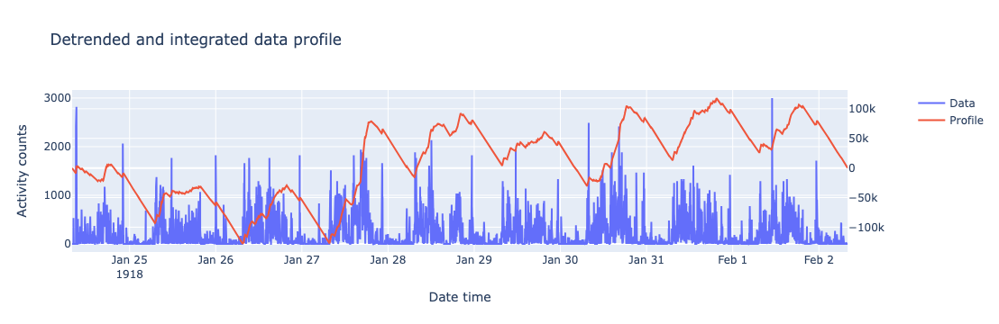

In [7]:
# Create figure with secondary y-axis
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add traces
fig.add_trace(
    go.Scatter(x=raw.activity.index.astype(str),y=raw.activity.values, name='Data'),
    secondary_y=False,
)
fig.add_trace(
    go.Scatter(x=raw.activity.index.astype(str),y=profile, name='Profile'),
    secondary_y=True,
)

# Add figure title
fig.update_layout(
    title_text="Detrended and integrated data profile"
)

# Set x-axis title
fig.update_xaxes(title_text="Date time")
# Set y-axes titles
fig.update_yaxes(title_text="Activity counts", secondary_y=False)
#fig.update_yaxes(title_text="<b>secondary</b> yaxis title", secondary_y=True)

fig.show()

In [8]:
n = 1000
segments = Fractal.segmentation(profile, n)

In [9]:
len(profile)

12961

In [10]:
segments.shape

(12, 1000)

In [11]:
local_fluctuations = [Fractal.local_msq_residuals(segment,deg=1) for segment in segments]

In [12]:
Fractal.q_th_order_mean_square(local_fluctuations,q=2)

np.float64(17613.535942976756)

In [13]:
n_array = np.geomspace(10, 1440, num=50, endpoint=True, dtype=int) # Numbers spaced evenly on a log scale, ranging from an ultradian time scale (10 min.) to a circadian one (1440 min, i.e. 24h)

In [15]:
F_n = Fractal.dfa(raw.activity,n_array,deg=1)

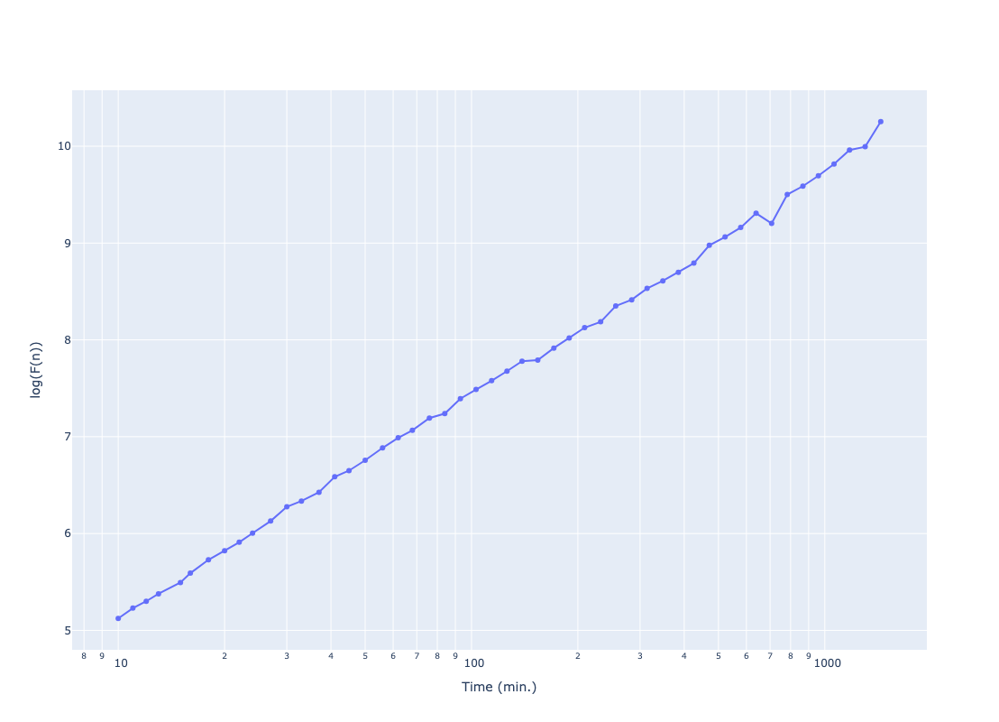

In [16]:
fig = go.Figure(data=[
    go.Scatter(x=n_array,y=np.log(F_n), name='Data fluctuation',mode='markers+lines')])
fig.update_layout(
    height=800, width=800,
    xaxis=dict(title='Time (min.)',type='log'),
    yaxis=dict(title='log(F(n))')
)

In [17]:
Fractal.generalized_hurst_exponent(F_n, n_array, log=False)

(np.float64(0.996382744180578), np.float64(0.004809113976784806))

In [18]:
q_array = [1,2,3,4,5,6]

In [20]:
MF_F_n = Fractal.mfdfa(raw.activity,n_array,q_array,deg=1)

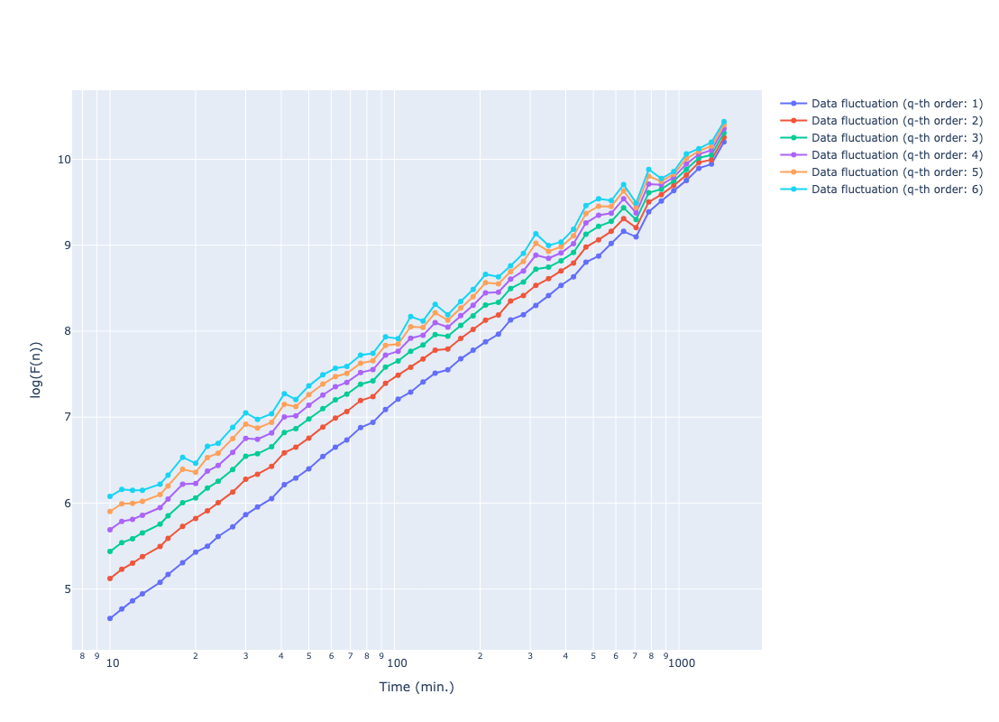

In [21]:
fig = go.Figure(data=[
    go.Scatter(x=n_array,y=np.log(MF_F_n[:,q]), name='Data fluctuation (q-th order: {})'.format(q_array[q]),mode='markers+lines') for q in range(len(q_array))])
fig.update_layout(
    height=800, width=800,
    xaxis=dict(title='Time (min.)',type='log'),
    yaxis=dict(title='log(F(n))')
)

In [22]:
mf_h_q = [Fractal.generalized_hurst_exponent(MF_F_n[:,q],n_array) for q in range(len(q_array))]

In [23]:
mf_h_q

[(np.float64(1.078789403267218), np.float64(0.005090112950945789)),
 (np.float64(0.996382744180578), np.float64(0.004809113976784806)),
 (np.float64(0.9498495984871702), np.float64(0.0049393201057842465)),
 (np.float64(0.9173765841355221), np.float64(0.005695765261621236)),
 (np.float64(0.8926070849788404), np.float64(0.006875225021534225)),
 (np.float64(0.8731126415786645), np.float64(0.008108469386111311))]

### SSA

In [5]:
fpath = os.path.join(os.path.dirname(circstudio.__file__))
#raw = circStudio.io.read_atr(os.path.join(fpath, 'data', 'test_sample_atr.txt'))
raw = circstudio.io.read_awd(os.path.join(fpath, 'data', 'example_01.AWD'),
                             start_time='1918-01-24 08:00:00',
                             period='9 days')

In [6]:
mySSA = circstudio.SSA(raw.activity, window_length='24h')

In [8]:
mySSA.build_trajectory_matrix().shape

(1440, 11522)

In [9]:
mySSA.fit()

In [10]:
mySSA.variance_explained.sum()

np.float64(1.0)

In [11]:
layout = go.Layout(
    height=600,
    width=800,
    title="Scree diagram",
    xaxis=dict(title="Singular value index", type='log', showgrid=True, gridwidth=1, gridcolor='LightPink', title_font = {"size": 20}),
    yaxis=dict(title=r'$\lambda_{k} / \lambda_{tot}$', type='log', showgrid=True, gridwidth=1, gridcolor='LightPink', ),
    showlegend=False
)

In [12]:
go.Figure(data=[go.Scatter(x=np.arange(0,len(mySSA.variance_explained)+1),y=mySSA.variance_explained)], layout=layout)

In [13]:
x_elem_0 = mySSA.get_component_matrix(r=0)

In [14]:
x_elem_0.shape

(1440, 11522)

In [15]:
w_corr_mat = mySSA.w_correlation_matrix(10)

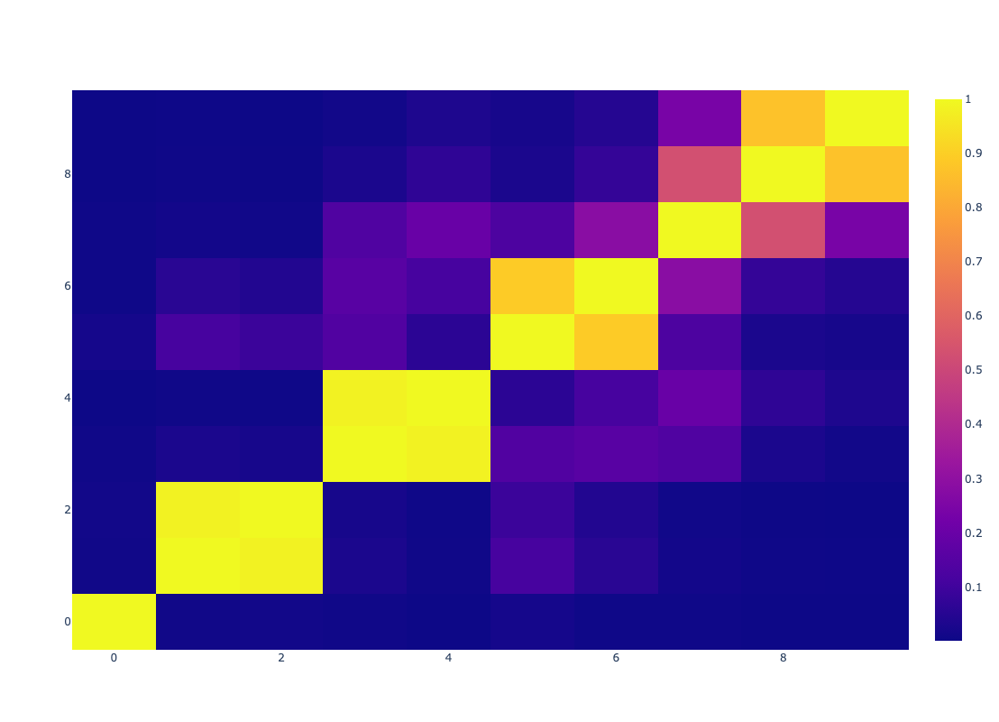

In [17]:
go.Figure(data=[go.Heatmap(z=w_corr_mat)], layout=go.Layout(height=800,width=800))

In [20]:
trend = mySSA.reconstruct_component(0)

In [21]:
# By definition, the reconstructed components must have the same dimension as the original signal:
trend.shape[0] == len(raw.activity.index)

True

In [22]:
et12 = mySSA.reconstruct_component([1,2])

In [23]:
et12 = mySSA.reconstruct_component([1,2])

In [24]:
et34 = mySSA.reconstruct_component([3,4])

In [25]:
layout = go.Layout(
    height=600,
    width=800,
    title="",
    xaxis=dict(title='Date Time'),
    yaxis=dict(title='Count'),
    shapes=[],
    showlegend=True
)


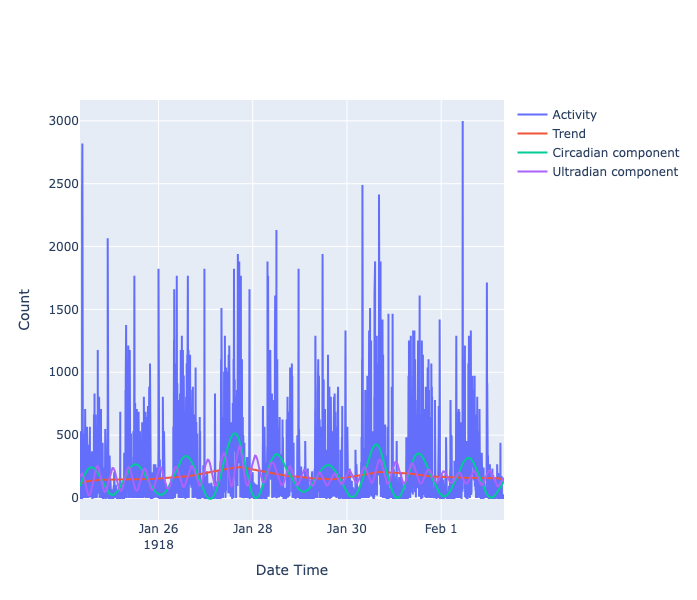

In [26]:
go.Figure(data=[
    go.Scatter(x=raw.activity.index,y=raw.activity, name='Activity'),
    go.Scatter(x=raw.activity.index,y=trend, name='Trend'),
    go.Scatter(x=raw.activity.index,y=trend+et12, name='Circadian component'),
    go.Scatter(x=raw.activity.index,y=trend+et34, name='Ultradian component')
], layout=layout)

In [26]:
rec = mySSA.reconstructed_signal([0,1,2,3,4,5,6])

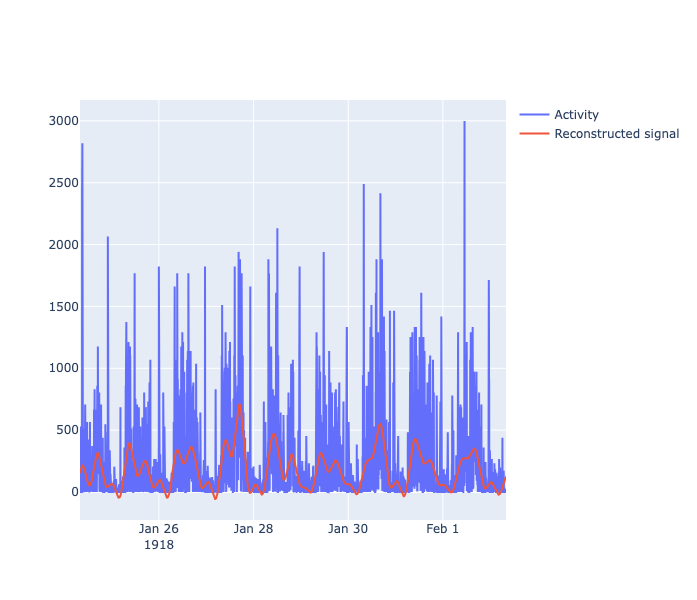

In [28]:
go.Figure(data=[
    go.Scatter(x=raw.activity.index, y=raw.activity, name='Activity'),
    go.Scatter(x=raw.activity.index, y=rec, name='Reconstructed signal')
], layout=go.Layout(height=600,width=800,showlegend=True))

### Feature-screening panel

In [2]:
fpath = os.path.join(os.path.dirname(circstudio.__file__))
#raw = circStudio.io.read_atr(os.path.join(fpath, 'data', 'test_sample_atr.txt'))

In [3]:
fs = FeatureScreening(data_path = os.path.join(fpath, 'data'),
                      factor='period',
                      levels=['p1', 'p2', 'p3'],
                      datetime_column='DATE/TIME',
                      light_column='LIGHT')

In [4]:
fs.calculate_panel()

,ID,Level,ADAT,IS,IV,L5,M10,RA,IS_light,IV_light,...,Acrophase,Exp_level,Forger_slope,Jewett_slope,Hannaysp_slope,Hannaytp_slope,Forger_rvalue,Jewett_rvalue,Hannaysp_rvalue,Hannaytp_rvalue
0,sb_04,p1,3.487812e+06,0.306149,0.703450,351.214286,3900.546770,0.834791,0.110607,0.534273,...,5.494040,1.110,0.067766,0.094322,0.010989,-0.269444,0.870648,0.853604,0.205316,-0.279457
1,sb_05,p1,3.083089e+06,0.345270,0.751531,243.436429,3322.267527,0.863457,0.156634,0.545709,...,5.251837,8.580,-0.006410,0.018315,-0.083333,-0.171329,-0.180021,0.400642,-0.858796,-0.414232
2,sb_06,p1,2.899595e+06,0.436028,0.880542,263.978571,3135.203919,0.844681,0.119370,0.651410,...,5.334569,1.600,-0.136447,-0.129121,-0.102564,0.069697,-0.956860,-0.910758,-0.761781,0.089605
3,sb_22,p2,3.253269e+06,0.332834,0.868988,622.618333,3027.341579,0.658836,0.060755,0.484123,...,4.316004,1.420,-0.023284,-0.010212,0.313480,-0.287990,-0.700349,-0.431291,0.996233,-0.414297
4,sb_20,p2,3.228698e+06,0.449905,1.166418,354.555185,2931.588158,0.784212,0.050208,0.616375,...,4.675384,0.310,-0.026552,-0.044118,0.111928,0.064103,-0.717455,-0.729197,0.925000,0.270126
5,sb_21,p2,3.360989e+06,0.450789,0.937193,410.958704,2797.116335,0.743797,0.064179,0.276894,...,4.550342,1.160,-0.032680,-0.031863,0.068627,0.023810,-0.875376,-0.814624,0.819288,0.054605
6,sb_25,p3,4.556550e+06,0.592259,0.686358,103.353000,4700.012430,0.956966,0.170527,0.458752,...,2.187701,8.860,-0.154971,-0.160526,-0.102632,-0.147870,-0.969390,-0.962181,-0.845109,-0.517608
7,sb_24,p3,5.847781e+06,0.320110,1.051924,647.191905,5148.424627,0.776662,0.134995,0.347513,...,2.226166,1.315,-0.273559,-0.289599,-0.360902,-1.104312,-0.976254,-0.966149,-0.947271,-0.730867
8,sb_26,p3,3.306047e+06,0.584550,0.702126,215.595333,3474.447270,0.883148,0.172471,0.404806,...,2.271138,1.290,-0.221978,-0.233700,-0.520879,-0.322844,-0.973627,-0.967645,-0.959026,-0.363911
9,sb_27,p3,2.742564e+06,0.388173,1.014524,261.945128,2876.248472,0.833060,0.170438,0.377756,...,1.641225,7.410,-0.196970,-0.220862,-0.123543,-0.351515,-0.959376,-0.948864,-0.835103,-0.432111


In [5]:
fdr, effsize = fs.permutation_test(n_permutations=10)

In [6]:
fdr

,ADAT,IS,IV,L5,M10,RA,IS_light,IV_light,L5_light,M10_light,...,Acrophase,Exp_level,Forger_slope,Jewett_slope,Hannaysp_slope,Hannaytp_slope,Forger_rvalue,Jewett_rvalue,Hannaysp_rvalue,Hannaytp_rvalue
0,0.363636,0.363636,0.363636,0.545455,0.181818,0.090909,0.090909,0.272727,0.363636,0.363636,...,0.090909,0.363636,0.090909,0.090909,0.090909,0.272727,0.363636,0.090909,0.090909,0.181818


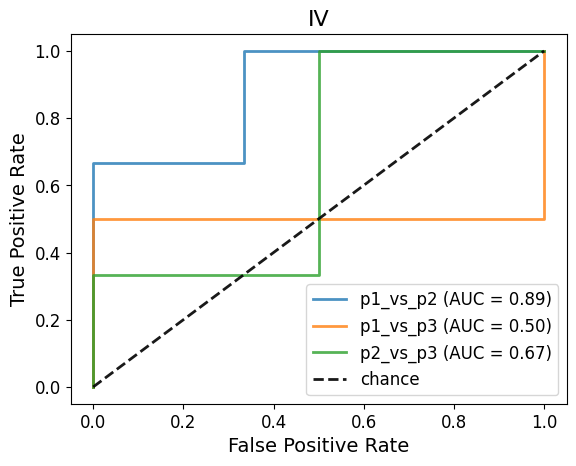

In [10]:
fs.draw_roc(feature='IV')

In [7]:
effsize

,ADAT,IS,IV,L5,M10,RA,IS_light,IV_light,L5_light,M10_light,...,Acrophase,Exp_level,Forger_slope,Jewett_slope,Hannaysp_slope,Hannaytp_slope,Forger_rvalue,Jewett_rvalue,Hannaysp_rvalue,Hannaytp_rvalue
0,0.572534,0.523901,0.615975,0.518903,0.776323,1.144747,2.862392,0.872149,0.518903,0.776323,...,7.584132,0.548559,1.694861,1.742319,1.440607,0.732831,0.904781,1.075452,2.8545,0.957916


In [2]:
# Create file path for sample files within the circStudio package
fpath = os.path.join(os.path.dirname(circstudio.__file__))

# Create a new Raw instance using awd RPX adaptor
raw = circstudio.io.read_rpx(os.path.join(fpath, 'data', 'test_sample_rpx_eng.csv'),
                             start_time='2015-07-04 12:00:00',
                             light_mode='White Light',
                             period='6 days',
                             language='ENG_UK')

In [3]:
raw.df

,Date,Time,Activity,Marker,White Light,Sleep/Wake,Interval Status
Date_Time,,,,,,,
2015-07-04 12:00:00,04/07/2015,12:00:00,310,0,92.49,1.0,ACTIVE
2015-07-04 12:00:30,04/07/2015,12:00:30,207,0,206.14,1.0,ACTIVE
2015-07-04 12:01:00,04/07/2015,12:01:00,403,0,94.52,1.0,ACTIVE
2015-07-04 12:01:30,04/07/2015,12:01:30,390,0,4766.62,1.0,ACTIVE
2015-07-04 12:02:00,04/07/2015,12:02:00,378,0,2834.25,1.0,ACTIVE
...,...,...,...,...,...,...,...
2015-07-10 11:58:00,10/07/2015,11:58:00,430,0,100.86,1.0,ACTIVE
2015-07-10 11:58:30,10/07/2015,11:58:30,299,0,92.49,1.0,ACTIVE
2015-07-10 11:59:00,10/07/2015,11:59:00,475,0,90.51,1.0,ACTIVE
